<a href="https://colab.research.google.com/github/Aldiss1/MPPM_Aldi/blob/main/JS10/JS10-Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab — Klasifikasi Data MNIST dengan ANN

**Mata Kuliah:** RTI235004 — Pembelajaran Mesin (Polinema)  
**Modul:** JS10 — Artificial Neural Network  
**Nama:** Aldi Surya Saputra


## Langkah 1 - Import Library

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)

print('TensorFlow version :', tf.__version__)

TensorFlow version : 2.21.0


## Langkah 2 - Load Data MNIST

In [22]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print('X_train_full :', X_train_full.shape)
print('y_train_full :', y_train_full.shape)
print('X_test       :', X_test.shape)
print('y_test       :', y_test.shape)

X_train_full : (60000, 28, 28)
y_train_full : (60000,)
X_test       : (10000, 28, 28)
y_test       : (10000,)


## Langkah 3 - Eksplorasi Data

In [23]:
print('Tipe data      :', X_train_full.dtype)
print('Nilai piksel    : min =', X_train_full.min(), ', max =', X_train_full.max())
print('Jumlah kelas    :', len(np.unique(y_train_full)))
print('Daftar kelas    :', np.unique(y_train_full))

df_label = pd.DataFrame({'label': y_train_full})
print('\nJumlah data tiap kelas (data latih):')
print(df_label['label'].value_counts().sort_index())

Tipe data      : uint8
Nilai piksel    : min = 0 , max = 255
Jumlah kelas    : 10
Daftar kelas    : [0 1 2 3 4 5 6 7 8 9]

Jumlah data tiap kelas (data latih):
label
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


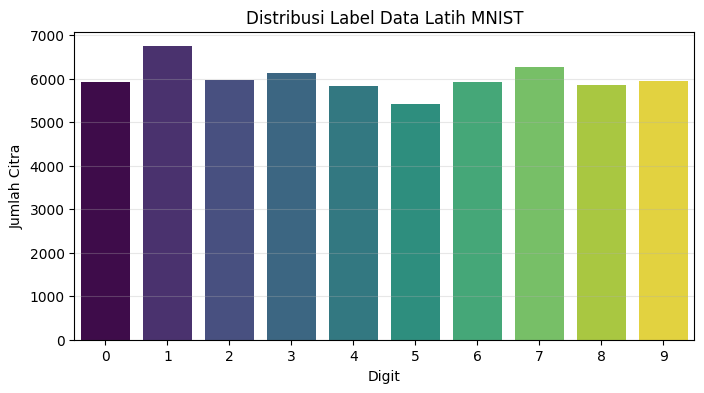

In [24]:
plt.figure(figsize=(8, 4))
sns.countplot(x=y_train_full, hue=y_train_full, palette='viridis', legend=False)
plt.title('Distribusi Label Data Latih MNIST')
plt.xlabel('Digit')
plt.ylabel('Jumlah Citra')
plt.grid(axis='y', alpha=0.3)
plt.show()

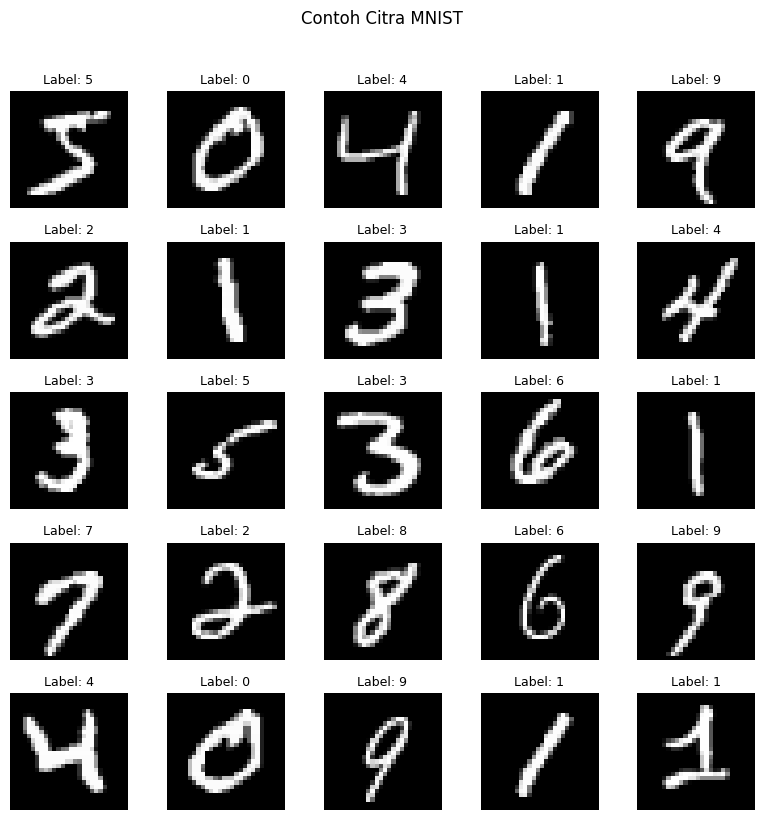

In [25]:
plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_full[i], cmap='gray')
    plt.title(f'Label: {y_train_full[i]}', fontsize=9)
    plt.axis('off')
plt.suptitle('Contoh Citra MNIST', y=1.02)
plt.tight_layout()
plt.show()

## Langkah 4 - Pra Pengolahan Data

Eksplorasi pra pengolahan yang dilakukan:

1. **Reshape** - citra 28×28 diratakan (flatten) menjadi 784 fitur, karena input ANN adalah vektor 1 dimensi.
2. **Normalisasi** - nilai piksel dari rentang 0–255 dibagi 255 sehingga menjadi 0–1. Hal ini mempercepat konvergensi saat training.
3. **Split validasi** - 10% data latih dipisahkan menjadi data validasi untuk memantau overfitting.

Untuk membandingkan pengaruh normalisasi, disiapkan juga data yang **tanpa normalisasi** (hanya reshape).

In [26]:
# Dengan normalisasi (/255.0)
X_norm = X_train_full.reshape(-1, 784).astype('float32') / 255.0
X_test_norm = X_test.reshape(-1, 784).astype('float32') / 255.0

# Tanpa normalisasi (hanya reshape, nilai piksel tetap 0-255)
X_raw = X_train_full.reshape(-1, 784).astype('float32')

# Split data latih dan validasi (90% : 10%)
X_train, X_val, y_train, y_val = train_test_split(
    X_norm, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full
)

X_train_raw, X_val_raw, y_train_raw, y_val_raw = train_test_split(
    X_raw, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full
)

print('X_train     :', X_train.shape)
print('X_val       :', X_val.shape)
print('X_test_norm :', X_test_norm.shape)
print('Range X_train :', X_train.min(), '-', X_train.max())
print('Range X_train_raw :', X_train_raw.min(), '-', X_train_raw.max())

X_train     : (54000, 784)
X_val       : (6000, 784)
X_test_norm : (10000, 784)
Range X_train : 0.0 - 1.0
Range X_train_raw : 0.0 - 255.0


## Langkah 5 - Fungsi Pembangun Model ANN

Fungsi `build_ann` membuat model ANN dengan arsitektur yang fleksibel:

* `hidden_layers` - list jumlah neuron tiap hidden layer, misal `[128, 64]` berarti 2 hidden layer
* `activation` - fungsi aktivasi hidden layer
* Output layer menggunakan `softmax` (10 kelas) dengan loss `sparse_categorical_crossentropy` sehingga label tidak perlu one-hot encoding.

In [27]:
def build_ann(hidden_layers=(128, 64), activation='relu', input_dim=784):
    model = models.Sequential(name='ANN_MNIST')
    model.add(layers.Input(shape=(input_dim,)))
    for n in hidden_layers:
        model.add(layers.Dense(n, activation=activation))
    model.add(layers.Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Contoh arsitektur
build_ann((128, 64), 'relu').summary()

Model: "ANN_MNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_41 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 6 - Eksplorasi Arsitektur dan Fungsi Aktivasi

Percobaan dilakukan dengan kombinasi:

| No | Arsitektur (hidden layer) | Aktivasi |
|---|---|---|
| 1 | 1 layer (128) | ReLU |
| 2 | 1 layer (128) | Sigmoid |
| 3 | 1 layer (128) | Tanh |
| 4 | 2 layer (256, 128) | ReLU |
| 5 | 2 layer (256, 128) | Sigmoid |
| 6 | 2 layer (256, 128) | Tanh |
| 7 | 3 layer (512, 256, 128) | ReLU |
| 8 | 3 layer (512, 256, 128) | Sigmoid |
| 9 | 3 layer (512, 256, 128) | Tanh |

Semua model dilatih 10 epoch dengan `batch_size=128` agar perbandingan adil.

In [28]:
EPOCHS = 10
BATCH = 128

arsitektur = {
    '1 layer (128)': (128,),
    '2 layer (256,128)': (256, 128),
    '3 layer (512,256,128)': (512, 256, 128),
}
aktivasi = ['relu', 'sigmoid', 'tanh']

hasil = []
histories = {}

for nama_ars, layers_ in arsitektur.items():
    for act in aktivasi:
        key = f'{nama_ars} | {act}'
        tf.keras.utils.set_random_seed(42)
        m = build_ann(layers_, act)
        h = m.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=EPOCHS, batch_size=BATCH, verbose=0
        )
        histories[key] = h.history
        hasil.append({
            'Arsitektur': nama_ars,
            'Aktivasi': act,
            'Jumlah Parameter': m.count_params(),
            'Val Accuracy': h.history['val_accuracy'][-1],
            'Val Loss': h.history['val_loss'][-1],
        })
        print(f'{key:45s} | val_acc = {h.history["val_accuracy"][-1]:.4f} | val_loss = {h.history["val_loss"][-1]:.4f}')

df_hasil = pd.DataFrame(hasil)
df_hasil

1 layer (128) | relu                          | val_acc = 0.9757 | val_loss = 0.0925
1 layer (128) | sigmoid                       | val_acc = 0.9648 | val_loss = 0.1219
1 layer (128) | tanh                          | val_acc = 0.9715 | val_loss = 0.0956
2 layer (256,128) | relu                      | val_acc = 0.9770 | val_loss = 0.1076
2 layer (256,128) | sigmoid                   | val_acc = 0.9727 | val_loss = 0.0887
2 layer (256,128) | tanh                      | val_acc = 0.9732 | val_loss = 0.0930
3 layer (512,256,128) | relu                  | val_acc = 0.9748 | val_loss = 0.1242
3 layer (512,256,128) | sigmoid               | val_acc = 0.9748 | val_loss = 0.0924
3 layer (512,256,128) | tanh                  | val_acc = 0.9750 | val_loss = 0.1050


,Arsitektur,Aktivasi,Jumlah Parameter,Val Accuracy,Val Loss
0,1 layer (128),relu,101770,0.975667,0.092466
1,1 layer (128),sigmoid,101770,0.964833,0.121950
2,1 layer (128),tanh,101770,0.971500,0.095643
3,"2 layer (256,128)",relu,235146,0.977000,0.107644
4,"2 layer (256,128)",sigmoid,235146,0.972667,0.088715
5,"2 layer (256,128)",tanh,235146,0.973167,0.092961
6,"3 layer (512,256,128)",relu,567434,0.974833,0.124210
7,"3 layer (512,256,128)",sigmoid,567434,0.974833,0.092446
8,"3 layer (512,256,128)",tanh,567434,0.975000,0.105005


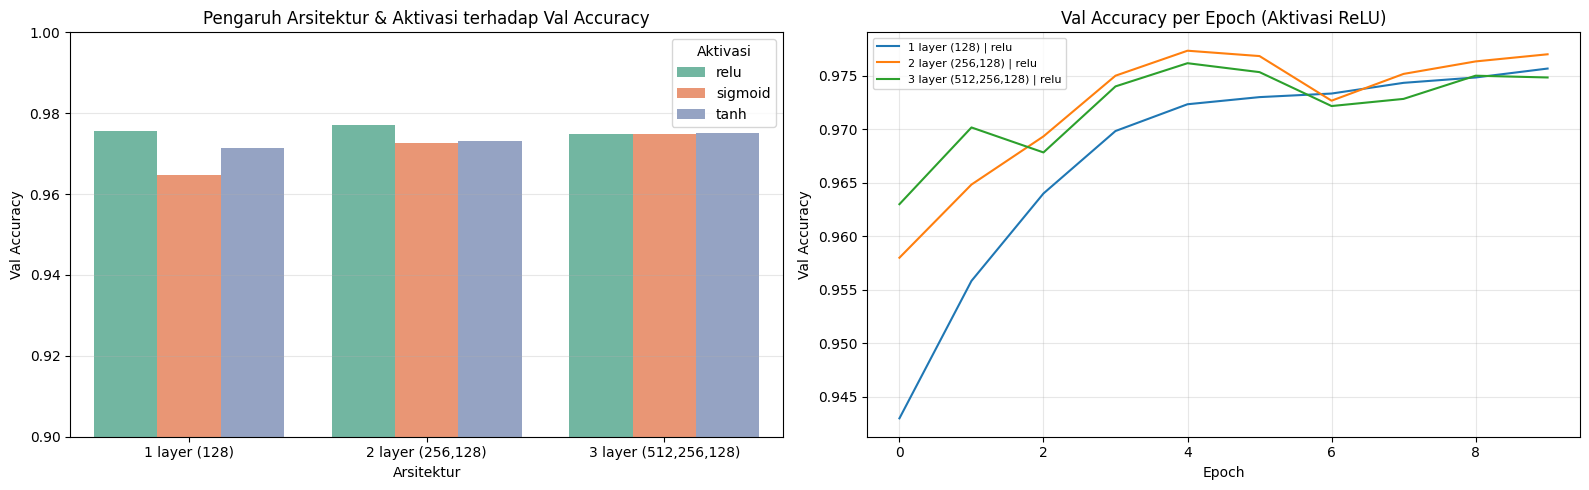

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=df_hasil, x='Arsitektur', y='Val Accuracy', hue='Aktivasi', ax=ax[0], palette='Set2')
ax[0].set_ylim(0.9, 1.0)
ax[0].set_title('Pengaruh Arsitektur & Aktivasi terhadap Val Accuracy')
ax[0].grid(axis='y', alpha=0.3)

for key, h in histories.items():
    if key.endswith('relu'):
        ax[1].plot(h['val_accuracy'], label=key)
ax[1].set_title('Val Accuracy per Epoch (Aktivasi ReLU)')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Val Accuracy')
ax[1].legend(fontsize=8)
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Langkah 7 - Eksplorasi Metode Pra Pengolahan (Normalisasi)

Perbandingan model dengan arsitektur terbaik, dilatih dengan dan tanpa normalisasi.

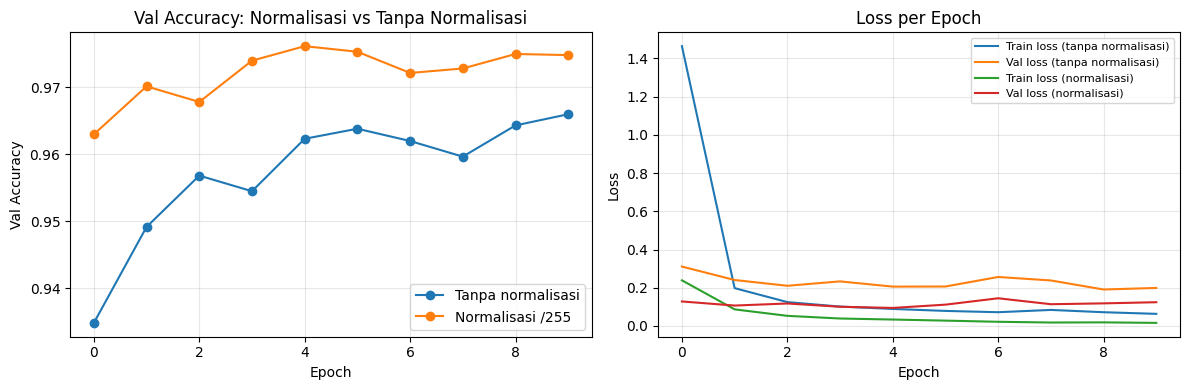

Val accuracy tanpa normalisasi : 0.9660000205039978
Val accuracy dengan normalisasi: 0.9748333096504211


In [30]:
tf.keras.utils.set_random_seed(42)
m_raw = build_ann((512, 256, 128), 'relu')
h_raw = m_raw.fit(
    X_train_raw, y_train_raw,
    validation_data=(X_val_raw, y_val_raw),
    epochs=EPOCHS, batch_size=BATCH, verbose=0
)

tf.keras.utils.set_random_seed(42)
m_norm = build_ann((512, 256, 128), 'relu')
h_norm = m_norm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH, verbose=0
)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(h_raw.history['val_accuracy'], label='Tanpa normalisasi', marker='o')
plt.plot(h_norm.history['val_accuracy'], label='Normalisasi /255', marker='o')
plt.title('Val Accuracy: Normalisasi vs Tanpa Normalisasi')
plt.xlabel('Epoch'); plt.ylabel('Val Accuracy'); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(h_raw.history['loss'], label='Train loss (tanpa normalisasi)')
plt.plot(h_raw.history['val_loss'], label='Val loss (tanpa normalisasi)')
plt.plot(h_norm.history['loss'], label='Train loss (normalisasi)')
plt.plot(h_norm.history['val_loss'], label='Val loss (normalisasi)')
plt.title('Loss per Epoch')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Val accuracy tanpa normalisasi :', h_raw.history['val_accuracy'][-1])
print('Val accuracy dengan normalisasi:', h_norm.history['val_accuracy'][-1])

## Langkah 8 - Model Final

Model final memakai konfigurasi terbaik hasil eksplorasi, dilatih lebih lama (50 epoch) dengan `EarlyStopping` dan `ReduceLROnPlateau`.

In [31]:
best = df_hasil.sort_values('Val Accuracy', ascending=False).iloc[0]
best_arch = arsitektur[best['Arsitektur']]
best_act = best['Aktivasi']

print('Konfigurasi terbaik:')
print('- Arsitektur :', best['Arsitektur'])
print('- Aktivasi   :', best_act)
print('- Val Acc    : {:.4f}'.format(best['Val Accuracy']))

Konfigurasi terbaik:
- Arsitektur : 2 layer (256,128)
- Aktivasi   : relu
- Val Acc    : 0.9770


In [32]:
tf.keras.utils.set_random_seed(42)
final_model = build_ann(best_arch, best_act)

cb_es = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_rl = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)

history_final = final_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50, batch_size=BATCH,
    callbacks=[cb_es, cb_rl], verbose=2
)

Epoch 1/50
422/422 - 5s - 12ms/step - accuracy: 0.9187 - loss: 0.2831 - val_accuracy: 0.9580 - val_loss: 0.1557 - learning_rate: 0.0010
Epoch 2/50
422/422 - 5s - 11ms/step - accuracy: 0.9675 - loss: 0.1089 - val_accuracy: 0.9648 - val_loss: 0.1228 - learning_rate: 0.0010
Epoch 3/50
422/422 - 3s - 8ms/step - accuracy: 0.9794 - loss: 0.0701 - val_accuracy: 0.9693 - val_loss: 0.1020 - learning_rate: 0.0010
Epoch 4/50
422/422 - 3s - 8ms/step - accuracy: 0.9855 - loss: 0.0500 - val_accuracy: 0.9750 - val_loss: 0.0924 - learning_rate: 0.0010
Epoch 5/50
422/422 - 6s - 15ms/step - accuracy: 0.9885 - loss: 0.0389 - val_accuracy: 0.9773 - val_loss: 0.0874 - learning_rate: 0.0010
Epoch 6/50
422/422 - 3s - 8ms/step - accuracy: 0.9908 - loss: 0.0300 - val_accuracy: 0.9768 - val_loss: 0.0932 - learning_rate: 0.0010
Epoch 7/50
422/422 - 3s - 8ms/step - accuracy: 0.9925 - loss: 0.0234 - val_accuracy: 0.9727 - val_loss: 0.1084 - learning_rate: 0.0010
Epoch 8/50
422/422 - 4s - 10ms/step - accuracy: 0.99

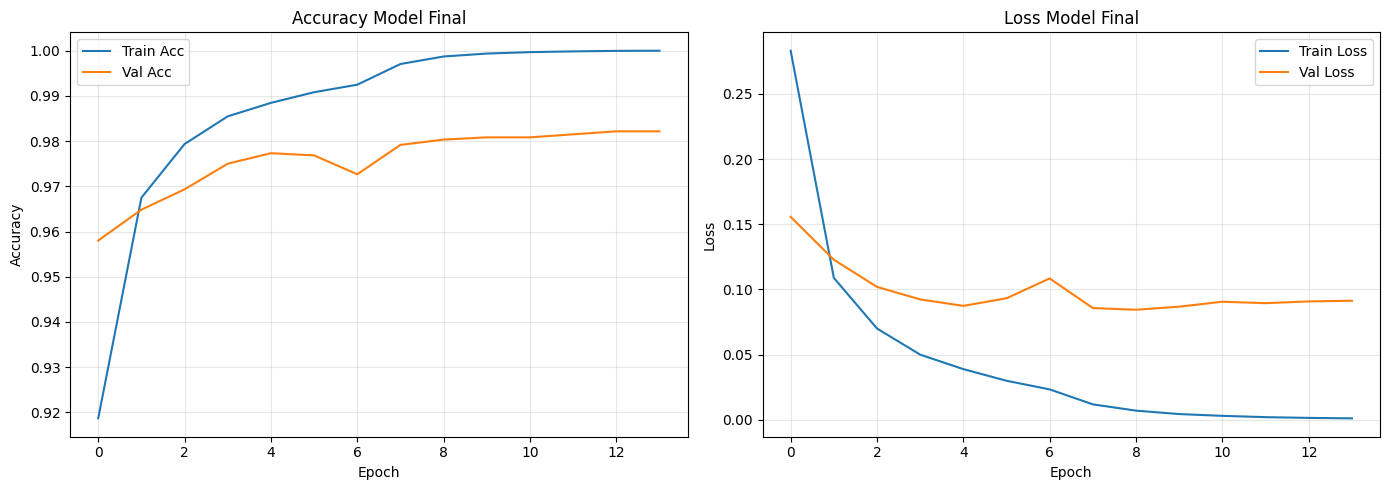

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(history_final.history['accuracy'], label='Train Acc')
ax[0].plot(history_final.history['val_accuracy'], label='Val Acc')
ax[0].set_title('Accuracy Model Final'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy')
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(history_final.history['loss'], label='Train Loss')
ax[1].plot(history_final.history['val_loss'], label='Val Loss')
ax[1].set_title('Loss Model Final'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss')
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Langkah 9 - Evaluasi Model dengan Data Test

In [34]:
test_loss, test_acc = final_model.evaluate(X_test_norm, y_test, verbose=0)
print('Test Loss     : {:.4f}'.format(test_loss))
print('Test Accuracy : {:.4f}'.format(test_acc))

y_pred_prob = final_model.predict(X_test_norm, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

print('\nAccuracy : {:.4f}'.format(accuracy_score(y_test, y_pred)))
print('Precision (macro) : {:.4f}'.format(precision_score(y_test, y_pred, average='macro')))
print('Recall (macro)    : {:.4f}'.format(recall_score(y_test, y_pred, average='macro')))
print('F1-Score (macro)  : {:.4f}'.format(f1_score(y_test, y_pred, average='macro')))

Test Loss     : 0.0701
Test Accuracy : 0.9826

Accuracy : 0.9826
Precision (macro) : 0.9825
Recall (macro)    : 0.9824
F1-Score (macro)  : 0.9824


              precision    recall  f1-score   support

           0     0.9868    0.9888    0.9878       980
           1     0.9938    0.9877    0.9907      1135
           2     0.9892    0.9806    0.9849      1032
           3     0.9725    0.9802    0.9763      1010
           4     0.9877    0.9837    0.9857       982
           5     0.9830    0.9731    0.9780       892
           6     0.9813    0.9875    0.9844       958
           7     0.9798    0.9922    0.9860      1028
           8     0.9743    0.9733    0.9738       974
           9     0.9762    0.9772    0.9767      1009

    accuracy                         0.9826     10000
   macro avg     0.9825    0.9824    0.9824     10000
weighted avg     0.9826    0.9826    0.9826     10000



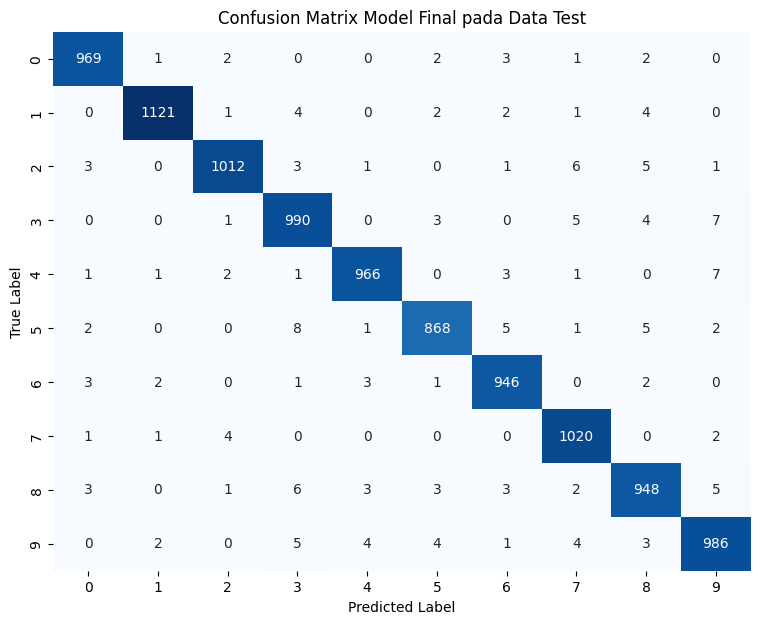

In [35]:
print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label'); plt.ylabel('True Label')
plt.title('Confusion Matrix Model Final pada Data Test')
plt.show()

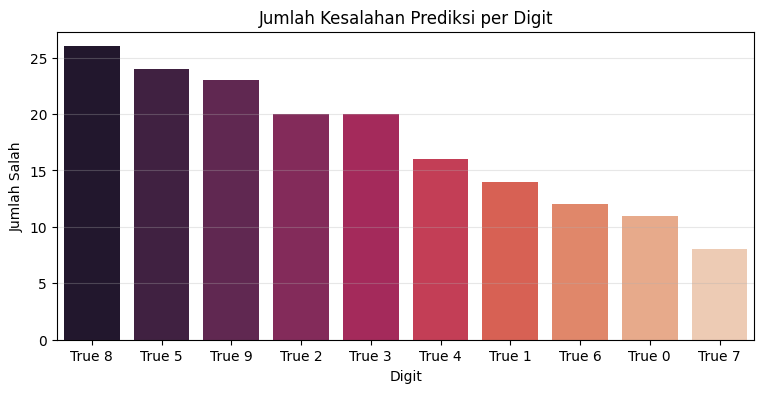

Total kesalahan: 174 dari 10000 citra


In [36]:
# Kesalahan per kelas: prediksi paling sering salah ke kelas lain
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
cm_df = pd.DataFrame(cm_off, index=[f'True {i}' for i in range(10)], columns=[f'Pred {i}' for i in range(10)])
salah = cm_df.sum(axis=1).sort_values(ascending=False)

plt.figure(figsize=(9, 4))
sns.barplot(x=salah.index, y=salah.values, hue=salah.index, palette='rocket', legend=False)
plt.title('Jumlah Kesalahan Prediksi per Digit')
plt.xlabel('Digit'); plt.ylabel('Jumlah Salah')
plt.grid(axis='y', alpha=0.3)
plt.show()

print('Total kesalahan:', salah.sum(), 'dari', len(y_test), 'citra')

## Langkah 10 - Visualisasi Prediksi

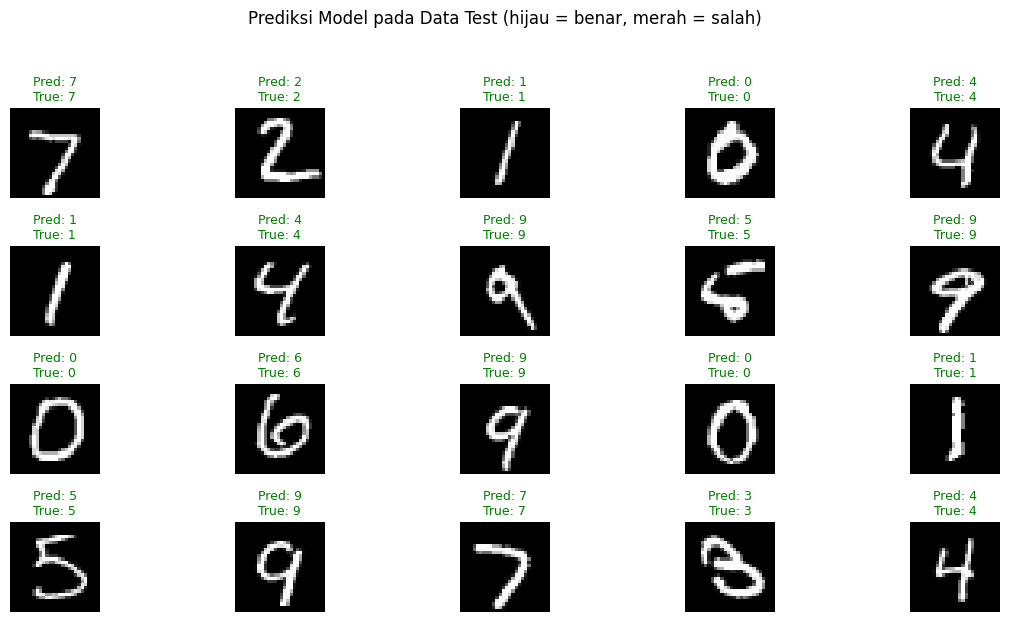

In [37]:
plt.figure(figsize=(12, 6))
for i in range(20):
    plt.subplot(4, 5, i + 1)
    color = 'green' if y_pred[i] == y_test[i] else 'red'
    plt.imshow(X_test[i], cmap='gray')
    plt.title(f'Pred: {y_pred[i]}\nTrue: {y_test[i]}', fontsize=9, color=color)
    plt.axis('off')
plt.suptitle('Prediksi Model pada Data Test (hijau = benar, merah = salah)', y=1.03)
plt.tight_layout()
plt.show()

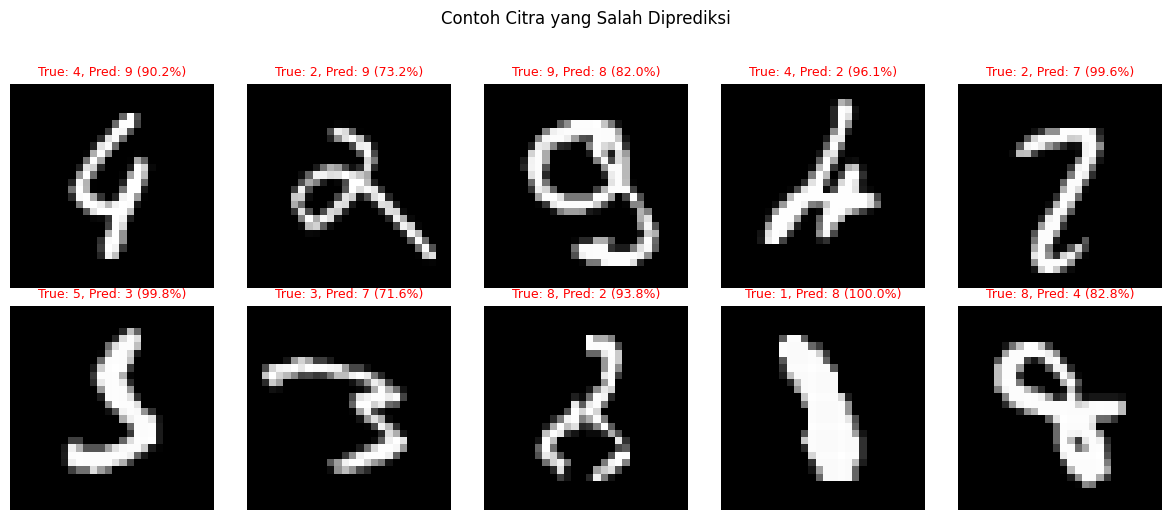

In [38]:
# Contoh citra yang salah diprediksi
idx_salah = np.where(y_pred != y_test)[0][:10]

plt.figure(figsize=(12, 5))
for i, idx in enumerate(idx_salah):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx], cmap='gray')
    plt.title(f'True: {y_test[idx]}, Pred: {y_pred[idx]} ({y_pred_prob[idx][y_pred[idx]]*100:.1f}%)', fontsize=9, color='red')
    plt.axis('off')
plt.suptitle('Contoh Citra yang Salah Diprediksi', y=1.03)
plt.tight_layout()
plt.show()

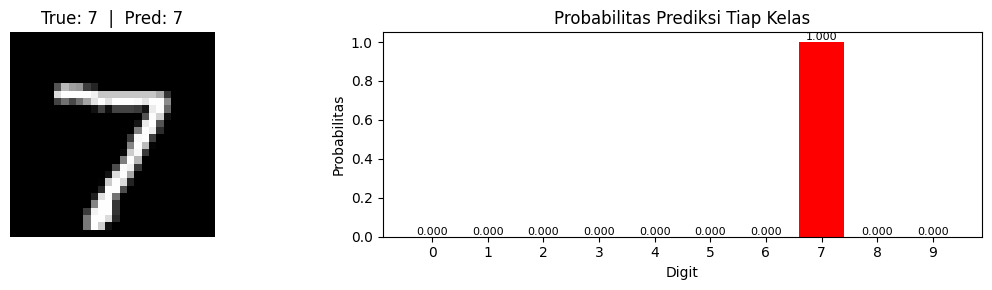

In [39]:
# Probabilitas prediksi untuk satu citra test
idx = 0
prob = y_pred_prob[idx]

plt.figure(figsize=(12, 3))
plt.subplot(1, 2, 1)
plt.imshow(X_test[idx], cmap='gray')
plt.title(f'True: {y_test[idx]}  |  Pred: {y_pred[idx]}')
plt.axis('off')

plt.subplot(1, 2, 2)
bars = plt.bar(range(10), prob, color=['red' if i == y_pred[idx] else 'steelblue' for i in range(10)])
plt.xticks(range(10)); plt.xlabel('Digit'); plt.ylabel('Probabilitas')
plt.title('Probabilitas Prediksi Tiap Kelas')
plt.ylim(0, 1.05)
for b, p in zip(bars, prob):
    plt.text(b.get_x() + b.get_width()/2, p + 0.01, f'{p:.3f}', ha='center', fontsize=8)
plt.tight_layout()
plt.show()

## Langkah 11 - Simpan Model

In [40]:
final_model.save('mnist_ann_model.keras')
print('Model disimpan sebagai mnist_ann_model.keras')

Model disimpan sebagai mnist_ann_model.keras
